# 03 · Protocol Segmentation and Analysis States

Phase 1 mapped every tag to a protocol segment (`src/data/protocol.py`). This notebook checks whether participants
actually did what the protocol prescribed, identifies valid reference periods, and defines **analysis states that are
comparable across the two protocol versions**. These states are used in every later notebook.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.visualization import plots as P

P.set_style()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
PROCESSED = ROOT / "data" / "processed"; INTERIM = ROOT / "data" / "interim"
C = P.COND_COLORS

w = pd.read_csv(PROCESSED / "windows.csv")
seg = pd.read_csv(INTERIM / "segments.csv")
print(f"{len(seg):,} segments · {len(w):,} windows")

1,064 segments · 12,346 windows


## 1 · Did participants pedal at the prescribed cadence?

The wrist oscillates once per foot-down, so cadence ≈ ACC dominant frequency / 2. Per-window estimates are noisy
because movement at the wrist is small with the hands on the handlebars. Each participant's median per stage is
shown, then the median across participants.

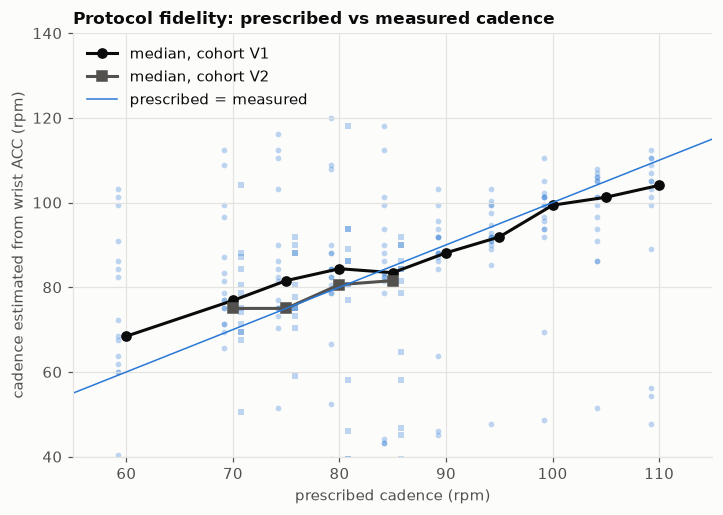

cohort,V1,V2
rpm,,
60,68.400,NaN
70,76.900,75.000
75,81.600,75.000
80,84.400,80.600
85,83.400,81.600
90,88.100,NaN
95,91.900,NaN
100,99.400,NaN
105,101.200,NaN


In [2]:
a = w[(w.condition == "AEROBIC") & w.segment.str.match(r"rpm_\d+$") & w.acc_valid].copy()
a["rpm"] = a.segment.str[4:].astype(int)
a["cadence_acc"] = a.acc_dom_freq_per_min / 2
per = a.groupby(["cohort", "subject_id", "rpm"]).cadence_acc.median().reset_index()
fig, ax = plt.subplots(figsize=(7.5, 5))
for coh, mk in [("V1", "o"), ("V2", "s")]:
    d = per[per.cohort == coh]
    ax.scatter(d.rpm + (0.8 if coh == "V2" else -0.8), d.cadence_acc, s=14, color=C["AEROBIC"], alpha=0.3, marker=mk, lw=0)
    med = d.groupby("rpm").cadence_acc.median()
    ax.plot(med.index, med.values, marker=mk, color=P.TEXT if coh == "V1" else P.TEXT_2, lw=2, label=f"median, cohort {coh}")
ax.plot([55, 115], [55, 115], color=C["AEROBIC"], lw=1, label="prescribed = measured")
ax.set_xlabel("prescribed cadence (rpm)"); ax.set_ylabel("cadence estimated from wrist ACC (rpm)")
ax.set_xlim(55, 115); ax.set_ylim(40, 140); ax.legend(loc="upper left")
ax.set_title("Protocol fidelity: prescribed vs measured cadence", loc="left")
P.save(fig, "03_cadence_fidelity"); plt.show()
per.groupby(["cohort", "rpm"]).cadence_acc.median().unstack(0).round(1)

From 85 rpm upward, the measured cadence is within ~2–6 rpm of the prescription (cohort V1 medians: 83, 88, 92,
99, 101, 104 rpm for 85–110). At 60–75 rpm participants pedalled **7–9 rpm faster than the metronome** (68, 77,
82 rpm), because a very slow cadence feels unnatural on a spinning bike. So the early stages were less different
from each other than intended, and workload progression came mostly from resistance and the higher-cadence stages.
The wrist accelerometer independently confirms that the protocol was followed.

## 2 · Is there a resting reference in the exercise sessions?

Candidate reference periods, compared on wrist movement (SD of |ACC| over 1 s; seated still ≈ 0.007 g):

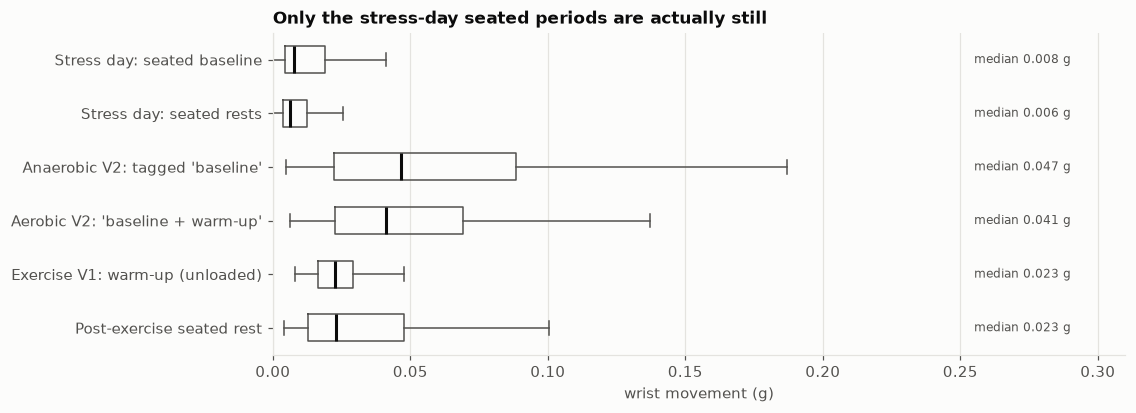

In [3]:
cand = {
    "Stress day: seated baseline": w[w.state == "SEATED_BASELINE"],
    "Stress day: seated rests": w[w.state == "SEATED_REST"],
    "Anaerobic V2: tagged 'baseline'": w[w.state == "PRE_EXERCISE_BASELINE"],
    "Aerobic V2: 'baseline + warm-up'": w[(w.condition == "AEROBIC") & (w.segment == "baseline_warmup")],
    "Exercise V1: warm-up (unloaded)": w[(w.cohort == "V1") & (w.condition != "STRESS") & (w.segment == "warmup")],
    "Post-exercise seated rest": w[w.state == "POST_EXERCISE_REST"],
}
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (name, d) in enumerate(cand.items()):
    v = d.acc_movement.dropna()
    ax.boxplot(v.clip(upper=0.25), positions=[i], vert=False, widths=0.5, showfliers=False,
               medianprops=dict(color=P.TEXT, lw=2), boxprops=dict(color=P.TEXT_2), whiskerprops=dict(color=P.TEXT_2), capprops=dict(color=P.TEXT_2))
    ax.text(0.255, i, f"median {v.median():.3f} g", va="center", fontsize=8, color=P.TEXT_2)
ax.set_yticks(range(len(cand)), list(cand)); ax.invert_yaxis(); ax.set_xlim(0, 0.31)
ax.set_xlabel("wrist movement (g)"); ax.grid(axis="y", visible=False)
ax.set_title("Only the stress-day seated periods are actually still", loc="left")
P.save(fig, "03_reference_periods"); plt.show()

The V2 exercise "baselines" happened in a group spinning room. Wrist movement there is ~6× higher than seated
stillness, about the same as pedalling. Participants were adjusting bikes, talking and moving. The V1 exercise sessions
start directly with unloaded pedalling. **No exercise session contains a usable resting baseline.**

**Decision:** the resting reference for every participant is the **seated baseline of the stress day**. It is
recorded on a different day, so day-to-day variability is part of any "change from rest". This is stated wherever it
is used. The 30 participants with all three protocols have this reference. f14–f18 have stress data only.

## 3 · Ambiguous sessions

- **AEROBIC/S03**: the data-constraints file says the participant "reached 90 rpm". The last tagged stage shows a
  wrist rhythm of 86–90 rpm. The following 240-s block has low, irregular movement (no rhythmic pedalling), so it is a
  genuine cooldown. Labels unchanged.
- **AEROBIC/S11_b**: movement before its only tag is cooldown-like, not 110-rpm pedalling. It is **excluded** from all
  analyses (state = none).

In [4]:
s3 = w[(w.condition == "AEROBIC") & (w.session_id == "S03") & w.segment.isin(["rpm_85", "cooldown"])]
s3.groupby("segment")[["acc_movement", "acc_periodicity", "acc_dom_freq_per_min"]].median().round(3)

,acc_movement,acc_periodicity,acc_dom_freq_per_min
segment,,,
cooldown,0.015,0.114,198.750
rpm_85,0.026,0.283,88.125


## 4 · Analysis states, comparable across protocol versions

| Analysis state | Definition | Why |
|---|---|---|
| `REST_SEATED` | stress-day seated baseline | only true resting reference |
| `STRESS_RECOVERY` | second half of each seated rest | avoids carry-over from the preceding task (as the authors did) |
| `STRESS_TMCT` | Trier Mental Challenge Test | the main stressor; present in both versions |
| `STRESS_SHORT` | opinion, opposite opinion, subtraction (30 s each), Stroop (V1) | short tasks, analysed separately |
| `AEROBIC_MODERATE` | 70, 75, 80 rpm, plus the first 3 min of 85 rpm | stages shared by V1 and V2 with similar exposure time |
| `AEROBIC_PEAK` | last 2 min of the final completed stage | highest workload each person reached |
| `SPRINT` | all-out sprints | movement and EDA only; HR unmeasurable (notebook 02) |
| `POST_SPRINT` | first 2 min of the cooldown after each sprint | the only window where the anaerobic HR response is measurable |
| `POST_EXERCISE_REST` | seated rest after exercise | recovery |

In [5]:
def analysis_state(r):
    if r.condition == "AEROBIC" and r.session_id == "S11_b":
        return None
    if r.state == "SEATED_BASELINE":
        return "REST_SEATED"
    if r.state == "SEATED_REST":
        seg_dur = r.seg_duration
        return "STRESS_RECOVERY" if r.t_in_segment_s >= seg_dur / 2 else None
    if r.state == "STRESS_TASK":
        return "STRESS_TMCT" if r.segment == "tmct" else "STRESS_SHORT"
    if r.state == "AEROBIC_STAGE":
        if r.segment in ("rpm_70", "rpm_75", "rpm_80"):
            return "AEROBIC_MODERATE"
        if r.segment == "rpm_85" and r.t_in_segment_s + 30 <= 180:
            return "AEROBIC_MODERATE"
        return None  # peak assigned below
    if r.state == "SPRINT":
        return "SPRINT"
    if r.condition == "ANAEROBIC" and r.segment.startswith("cooldown") and r.t_in_segment_s + 30 <= 120:
        return "POST_SPRINT"
    if r.state == "POST_EXERCISE_REST":
        return "POST_EXERCISE_REST"
    return None

dur = seg.set_index(["condition", "session_id", "segment"]).duration_s
w["seg_duration"] = [dur.get((c, s, g), np.nan) for c, s, g in zip(w.condition, w.session_id, w.segment)]
w["analysis_state"] = [analysis_state(r) for r in w.itertuples()]

# AEROBIC_PEAK: last 2 min of the final completed exercise segment of each aerobic session
ex = w[(w.condition == "AEROBIC") & (w.phase == "exercise") & (w.session_id != "S11_b")]
for sid, g in ex.groupby("session_id"):
    last_seg = g.loc[g.end_s.idxmax(), "segment"]
    gs = g[g.segment == last_seg]
    peak_idx = gs[gs.end_s >= gs.end_s.max() - 120].index
    w.loc[peak_idx, "analysis_state"] = "AEROBIC_PEAK"

w.to_csv(PROCESSED / "windows.csv", index=False)
STATES = ["REST_SEATED", "STRESS_RECOVERY", "STRESS_TMCT", "STRESS_SHORT", "AEROBIC_MODERATE",
          "AEROBIC_PEAK", "SPRINT", "POST_SPRINT", "POST_EXERCISE_REST"]
summary = (w[w.analysis_state.notna()].groupby("analysis_state")
           .agg(windows=("win_idx", "size"), participants=("subject_id", "nunique"),
                hr_valid=("hr_valid", "mean"), eda_valid=("eda_valid", "mean"))
           .reindex(STATES))
summary

,windows,participants,hr_valid,eda_valid
analysis_state,,,,
REST_SEATED,1344,36,0.600,0.942
STRESS_RECOVERY,1212,36,0.692,0.992
STRESS_TMCT,447,36,0.660,0.980
STRESS_SHORT,221,36,0.394,0.995
AEROBIC_MODERATE,1091,30,0.433,0.979
AEROBIC_PEAK,227,30,0.427,0.982
SPRINT,107,31,0.028,0.944
POST_SPRINT,742,31,0.117,0.969
POST_EXERCISE_REST,460,31,0.328,0.998


In [6]:
peak = w[w.analysis_state == "AEROBIC_PEAK"].groupby(["cohort", "session_id"]).segment.first()
print("Final completed stage used as AEROBIC_PEAK:")
print(peak.groupby("cohort").value_counts().to_string())

Final completed stage used as AEROBIC_PEAK:
cohort  segment        
V1      rpm_110            14
        rpm_110_partial     1
        rpm_85              1
        rpm_95              1
V2      rpm_90_95          10
        rpm_85              3


`AEROBIC_PEAK` is not the same workload for everyone. V1 mostly reached 110 rpm at 50% of maximum resistance. V2
reached 90/95 rpm, or stayed at 85 rpm in the group that skipped the last stage. Absolute power is unknown in both
cases. Peak comparisons are therefore within cohort, or framed as each person's highest *protocol* stage.